# 5 · The decision chart: what spacing would a 30-year doublet need?

**KAI-GeoEnergy · KAI Reservoir Lab · Utah FORGE, Milford, Utah (USA)**

**This well pair is a test bed, not a power plant.** 16A and 16B are about 96 m apart. At 10 kg/s their produced water starts to cool within a year (notebooks 3 and 4). The question here is what a doublet built for 30 years would need: how far apart, at what rate, and with what uncertainty.

**Method.**
1. **A proxy doublet.** Two parallel horizontal laterals with 480 m of open hole each, like 16A and 16B. They sit in a stimulated slab of fractured granite, which reaches 100 m beyond each well. The slab is an equivalent continuum, with the same physics as the FORGE model: TVD heat advection, conduction, and a log-normal, spatially correlated permeability. Rates are balanced and reinjection is at 60 °C.
2. **Tied to FORGE.** The slab thickness is the one free knob. At 96 m spacing and 10 kg/s, it is set so that the proxy gives the FORGE ensemble's 30-year temperature (P10, P50, P90; notebook 4, Barton–Bandis). The chart then keeps that thickness and changes only spacing and rate.
3. **A surrogate.** A Gaussian-process regression is trained on full proxy runs and tested on held-out runs. It fills the chart with P10–P90 values from a Monte Carlo over the uncertain inputs: thickness, heterogeneity, correlation length and rock conductivity. Outside its training range it returns nothing, and a full run is needed there.
4. **Variance-based sensitivity.** Sobol indices of the 30-year temperature, from the surrogate.

**The criterion.** A 30-year doublet here is one whose produced temperature after 30 years is still within 10 % of the way from initial to reinjection temperature: at least 198.6 °C for 214 °C initial and 60 °C reinjection.

**Assumptions that FORGE data do not show.** At larger spacings, stimulation would make a network of the same kind (same thickness, heterogeneity and conductivity), and that network would connect the wells. The pressure needed grows with spacing; the chart reports it as a multiple of the August 2024 pressure difference.

**Labels.** Proxy runs are **simulated**. Chart values and Sobol indices are **surrogate** values, with the surrogate's error published below.

In [1]:
import json, pathlib, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import forge_tools as ft
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "legend.frameon": False, "savefig.bbox": "tight", "savefig.facecolor": "white"})
GOLD, CHARCOAL, GRANITE, BLUE, GREY = "#c9a227", "#26292e", "#b5838d", "#2a78d6", "#8a8f98"     # KAI energy palette
pathlib.Path("results").mkdir(exist_ok=True); pathlib.Path("figures").mkdir(exist_ok=True)
E = json.loads(pathlib.Path("results/kai_engine_phase4.json").read_text())      # KAI engine run (simulated)
ens = E["ensemble"]
def pct(d, f="{:.1f}"):
    fm = lambda v: v if isinstance(v, str) else f.format(v)
    return f"{fm(d['P50'])} ({fm(d['P10'])}–{fm(d['P90'])})"
print(E["label"]); print(f"ensemble: {ens['members'] - ens['failed']}/{ens['members']} members ran, {ens['calibration_converged']} calibrated")
Dd = E["decision"]
ch = Dd["chart"]

simulated (KAI Reservoir Lab TPFA solver, equivalent-continuum fractured granite); not field data
ensemble: 20/20 members ran, 20 calibrated


## Tie to FORGE

In [2]:
tie = Dd["tie_to_forge"]
display(pd.DataFrame({"slab thickness (m)": tie["slabs_m"], "proxy T year 30 at 96 m, 10 kg/s (°C)": np.round(tie["T30_c"], 1)}))
print("FORGE ensemble targets (°C):", {k: round(v, 1) for k, v in tie["targets_c"].items()})
print("slab thickness that reproduces them (m):", {k: (None if v is None else round(v, 0)) for k, v in tie["slab_m"].items()})
print(f"used: log-normal, median {Dd['slab_distribution']['median']:.0f} m, P10–P90 factor {Dd['slab_distribution']['factor']:.2f}; training range "
      f"{Dd['slab_training_range_m'][0]:.0f}–{Dd['slab_training_range_m'][1]:.0f} m")

,slab thickness (m),"proxy T year 30 at 96 m, 10 kg/s (°C)"
0,8.0,88.2
1,16.0,89.5
2,32.0,92.2
3,64.0,98.3
4,128.0,111.4
5,256.0,147.4


FORGE ensemble targets (°C): {'P10': 115.7, 'P50': 129.2, 'P90': 146.9}
slab thickness that reproduces them (m): {'P10': 139.0, 'P50': 180.0, 'P90': 253.0}
used: log-normal, median 180 m, P10–P90 factor 1.35; training range 99–355 m


## The surrogate and its error

Its error on held-out full runs, and in 5-fold cross-validation. A quadratic regression is shown as the baseline, to show the Gaussian process is needed.

,output,test,RMSE,max |error|,R²,90 % band coverage,quadratic baseline RMSE
0,T_prod_end_c,held out,10.253,22.991,0.9591,0.72,22.478
1,T_prod_end_c,cross validation,7.519,29.650,0.9758,0.91,20.577
2,power_mean_mw,held out,0.869,2.386,0.9882,0.88,1.060
3,power_mean_mw,cross validation,0.795,3.139,0.9891,0.93,0.936
4,dp_ratio_max,held out,4.506,15.677,0.7708,0.84,4.986
5,dp_ratio_max,cross validation,5.792,49.358,0.8268,0.86,5.905


100 training runs, 25 held-out runs, 0 failed


,spacing_m,rate_kg_s,full_P50_c,surrogate_P50_c,member_abs_error_c,fallback
0,100.0,10.0,126.354490,129.352970,"{'P10': 1.2587598080280884, 'P50': 4.166030209...",0
1,400.0,40.0,109.208755,120.559728,"{'P10': 4.248390063633491, 'P50': 7.1444614923...",0
2,600.0,80.0,86.862862,93.150297,"{'P10': 1.5022109347039079, 'P50': 3.303657668...",0


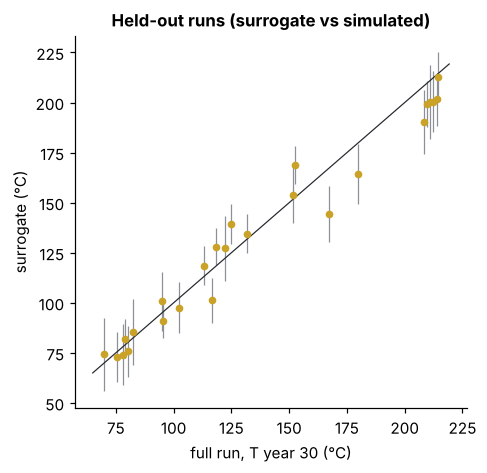

In [3]:
rows = []
for key, v in Dd["surrogate_validation"].items():
    for part in ("held_out", "cross_validation"):
        g, q_ = v[part]["gp"], v[part]["quadratic_baseline"]
        rows.append({"output": key, "test": part.replace("_", " "), "RMSE": round(g["rmse"], 3), "max |error|": round(g["max_abs"], 3), "R²": round(g["r2"], 4),
                     "90 % band coverage": round(g["coverage_90"], 2), "quadratic baseline RMSE": round(q_["rmse"], 3)})
display(pd.DataFrame(rows))
print(f"{Dd['training_runs']} training runs, {Dd['test_runs']} held-out runs, {Dd['failed_runs']} failed")
ho = Dd["held_out_predictions"]["T_prod_end_c"]
fig, ax = plt.subplots(figsize=(4.6, 4.4))
ax.errorbar(ho["full"], ho["surrogate"], yerr=1.645 * np.array(ho["std"]), fmt="o", color=GOLD, ms=4, ecolor=GREY, elinewidth=0.8)
lo, hi = min(ho["full"]) - 5, max(ho["full"]) + 5
ax.plot([lo, hi], [lo, hi], color=CHARCOAL, lw=0.8); ax.set_xlabel("full run, T year 30 (°C)"); ax.set_ylabel("surrogate (°C)")
ax.set_title("Held-out runs (surrogate vs simulated)"); fig.savefig("figures/forge_surrogate_error.png")
chk = pd.DataFrame(Dd["chart_full_run_checks"]); display(chk)

## The chart

,rate (kg/s),"spacing needed, P50 (m)","spacing needed, P10 (m)"
0,5.0,222.0,277.0
1,10.0,322.0,466.0
2,20.0,625.0,784.0
3,40.0,NaN,NaN
4,60.0,NaN,NaN
5,80.0,NaN,NaN


example: 400 m at 40 kg/s: T year 30 117 (98–141) °C; mean heat 18.2 (15.7–20.9) MWth; pressure difference 14.2 × the August 2024 value at today's network conductivity


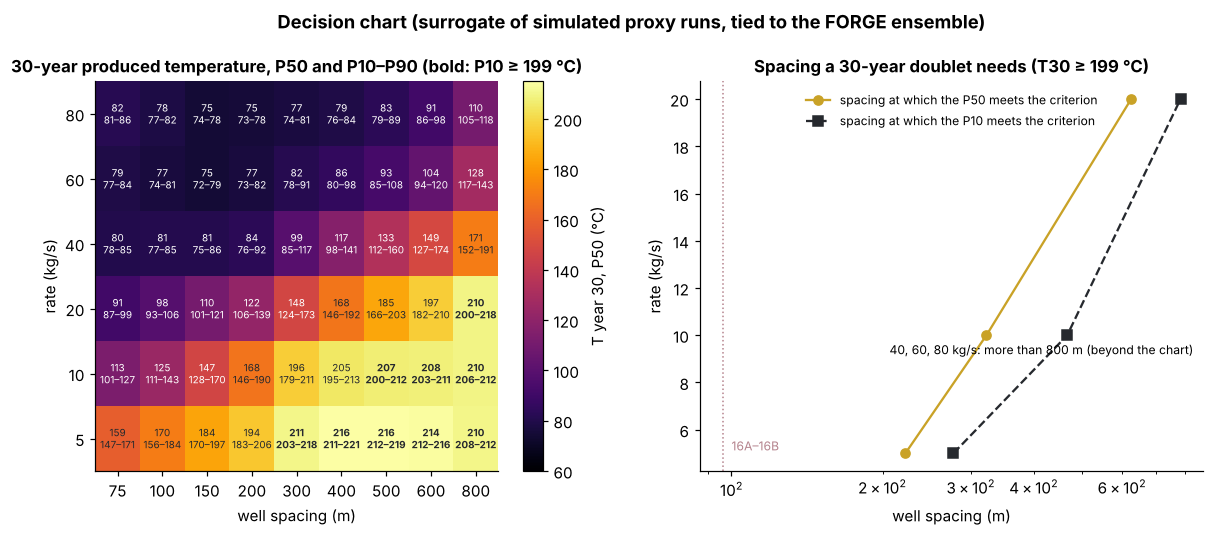

In [4]:
cells = pd.DataFrame([{**{k: c[k] for k in ("spacing_m", "rate_kg_s", "fallback_share")}, **({f"T30_{p}": c["T30_c"][p] for p in ("P10", "P50", "P90")} if "T30_c" in c else {}),
                        **({f"MW_{p}": c["power_mean_mw"][p] for p in ("P10", "P50", "P90")} if "T30_c" in c else {}),
                        **({"dp_ratio_P50": c["dp_ratio_max"]["P50"], "meets": c["meets_criterion_share"]} if "T30_c" in c else {})} for c in ch["cells"]])
crit = ch["T_criterion_c"]
Ls, Qs = ch["spacings_m"], ch["rates_kg_s"]
piv = cells.pivot(index="rate_kg_s", columns="spacing_m", values="T30_P50")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
im = ax[0].imshow(piv.values, origin="lower", cmap="inferno", vmin=60, vmax=215, aspect="auto")
for i, q in enumerate(piv.index):
    for j, L in enumerate(piv.columns):
        r = cells[(cells.rate_kg_s == q) & (cells.spacing_m == L)].iloc[0]
        if np.isfinite(r.get("T30_P50", np.nan)):
            ax[0].text(j, i, f"{r.T30_P50:.0f}\n{r.T30_P10:.0f}–{r.T30_P90:.0f}", ha="center", va="center", fontsize=6.5,
                       color="white" if r.T30_P50 < 150 else CHARCOAL, fontweight="bold" if r.T30_P10 >= crit else "normal")
ax[0].set_xticks(range(len(piv.columns))); ax[0].set_xticklabels([f"{L:.0f}" for L in piv.columns]); ax[0].set_yticks(range(len(piv.index))); ax[0].set_yticklabels([f"{q:.0f}" for q in piv.index])
ax[0].set_xlabel("well spacing (m)"); ax[0].set_ylabel("rate (kg/s)"); fig.colorbar(im, ax=ax[0], label="T year 30, P50 (°C)")
ax[0].set_title(f"30-year produced temperature, P50 and P10–P90 (bold: P10 ≥ {crit:.0f} °C)")
need = ch["spacing_needed_m"]
for lvl, c, mk in (("P50", GOLD, "o-"), ("P10", CHARCOAL, "s--")):
    xs = [need[str(int(q))][lvl] for q in Qs]
    ax[1].plot([x if x is not None else np.nan for x in xs], Qs, mk, color=c, label=f"spacing at which the {lvl} meets the criterion")
ax[1].axvline(96, color=GRANITE, lw=1, ls=":"); ax[1].text(100, 5, "16A–16B", color=GRANITE, fontsize=8, va="bottom")
beyond = [int(q) for q in Qs if need[str(int(q))]["P50"] is None]
if beyond:
    ax[1].text(0.98, 0.30, f"{', '.join(map(str, beyond))} kg/s: more than {max(Ls):.0f} m (beyond the chart)", transform=ax[1].transAxes, ha="right", fontsize=8)
ax[1].set_xscale("log"); ax[1].set_xlabel("well spacing (m)"); ax[1].set_ylabel("rate (kg/s)"); ax[1].legend(fontsize=8)
ax[1].set_title(f"Spacing a 30-year doublet needs (T30 ≥ {crit:.0f} °C)")
fig.suptitle("Decision chart (surrogate of simulated proxy runs, tied to the FORGE ensemble)", y=1.02, fontweight="bold")
fig.savefig("figures/forge_decision_chart.png")
rows = []
for q in Qs:
    n_ = need[str(int(q))]
    sel = cells[(cells.rate_kg_s == q)]
    rows.append({"rate (kg/s)": q, "spacing needed, P50 (m)": None if n_["P50"] is None else round(n_["P50"]), "spacing needed, P10 (m)": None if n_["P10"] is None else round(n_["P10"])})
display(pd.DataFrame(rows))
sel = cells[(cells.spacing_m == 400) & (cells.rate_kg_s == 40)].iloc[0]
print(f"example: 400 m at 40 kg/s: T year 30 {sel.T30_P50:.0f} ({sel.T30_P10:.0f}–{sel.T30_P90:.0f}) °C; mean heat {sel.MW_P50:.1f} ({sel.MW_P10:.1f}–{sel.MW_P90:.1f}) MWth; "
      f"pressure difference {sel.dp_ratio_P50:.1f} × the August 2024 value at today's network conductivity")

## Which inputs matter (Sobol)

,case,input,S1,ST,ST 90 % CI
0,forge_spacing_96m_10kgs,slab_m,0.580,0.580,0.54–0.62
1,forge_spacing_96m_10kgs,corr_m,0.239,0.238,0.22–0.26
2,forge_spacing_96m_10kgs,sigma_lnk,0.181,0.184,0.17–0.20
3,forge_spacing_96m_10kgs,lam,0.000,0.000,0.00–0.00
4,doublet_400m_40kgs,slab_m,0.967,0.970,0.92–1.02
5,doublet_400m_40kgs,corr_m,0.030,0.031,0.03–0.03
6,doublet_400m_40kgs,sigma_lnk,0.001,0.002,0.00–0.00
7,doublet_400m_40kgs,lam,-0.000,0.000,0.00–0.00
8,design_and_uncertainty,rate_kg_s,0.574,0.650,0.60–0.69
9,design_and_uncertainty,spacing_m,0.295,0.384,0.36–0.42


,p10_per_m,bg_aperture_factor,rotation_deg,stim_aperture_sigma,Kni,Vm
T30_10kgs_c,0.41,0.70,0.58,0.03,0.03,0.18
breakthrough_10kgs_y,0.28,0.42,0.55,-0.19,-0.13,0.31
max_feasible_rate_kg_s,-0.26,0.41,0.10,0.71,0.13,-0.50
stim_aperture_factor,0.17,-0.34,0.02,-0.70,-0.22,-0.11


rank correlations in the 20-member FORGE ensemble (the full model; too few members for Sobol)


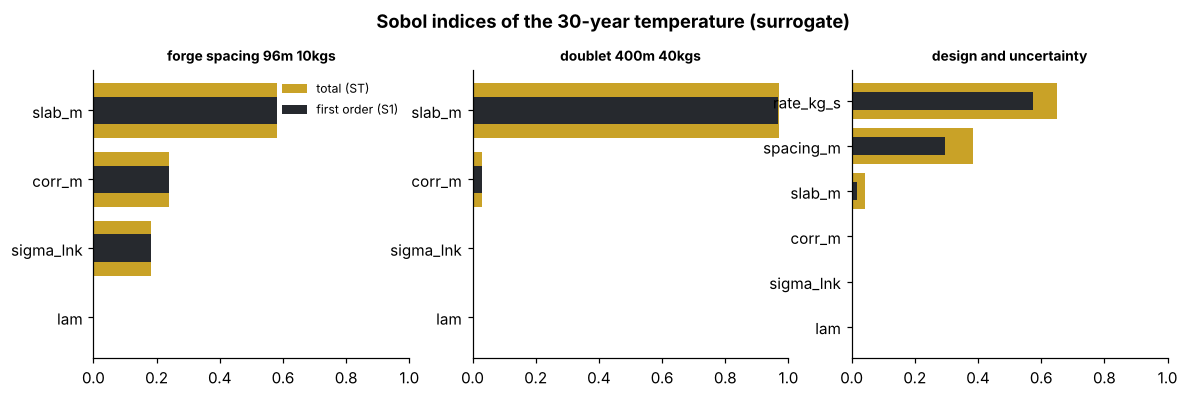

In [5]:
S = Dd["sobol_T30"]
fig, ax = plt.subplots(1, len(S), figsize=(4.2 * len(S), 3.4))
rows = []
for a_, (lab, s) in zip(ax, S.items()):
    names = s["ranking"]
    a_.barh(names, [s["indices"][n]["ST"] for n in names], color=GOLD, label="total (ST)")
    a_.barh(names, [s["indices"][n]["S1"] for n in names], color=CHARCOAL, height=0.4, label="first order (S1)")
    a_.invert_yaxis(); a_.set_xlim(0, 1); a_.set_title(lab.replace("_", " "), fontsize=9)
    for n in names:
        rows.append({"case": lab, "input": n, "S1": round(s["indices"][n]["S1"], 3), "ST": round(s["indices"][n]["ST"], 3),
                     "ST 90 % CI": f"{s['indices'][n]['ST_ci'][0]:.2f}–{s['indices'][n]['ST_ci'][1]:.2f}"})
ax[0].legend(fontsize=8); fig.suptitle("Sobol indices of the 30-year temperature (surrogate)", y=1.04, fontweight="bold")
fig.savefig("figures/forge_sobol.png"); display(pd.DataFrame(rows))
sp = E["spearman"]
display(pd.DataFrame({o: {i: round(v["rho"], 2) for i, v in d.items()} for o, d in sp.items()}).T)
print("rank correlations in the 20-member FORGE ensemble (the full model; too few members for Sobol)")

## Published numbers

In [6]:
now = {"criterion_c": crit, "slab_P50": Dd["slab_distribution"]["median"]}
for q in Qs:
    for lvl in ("P50", "P10"):
        now[f"need_{int(q)}_{lvl}"] = need[str(int(q))][lvl]
for key in Dd["surrogate_validation"]:
    now[f"rmse_{key}"] = Dd["surrogate_validation"][key]["held_out"]["gp"]["rmse"]
for lab, s in S.items():
    now[f"top_{lab}"] = s["ranking"][0]
published = {'criterion_c': 198.6, 'slab_P50': 180.27362267954922, 'need_5_P50': 222.04145430462154, 'need_5_P10': 276.78088987423286, 'need_10_P50': 322.0605024492923, 'need_10_P10': 466.46185518000175, 'need_20_P50': 625.3172825587562, 'need_20_P10': 784.2386270249092, 'need_40_P50': None, 'need_40_P10': None, 'need_60_P50': None, 'need_60_P10': None, 'need_80_P50': None, 'need_80_P10': None, 'rmse_T_prod_end_c': 10.252882067926288, 'rmse_power_mean_mw': 0.8685742039091628, 'rmse_dp_ratio_max': 4.505607979360255, 'top_forge_spacing_96m_10kgs': 'slab_m', 'top_doublet_400m_40kgs': 'slab_m', 'top_design_and_uncertainty': 'rate_kg_s'}
for k, v in published.items():
    x = now[k]
    if isinstance(v, str) or isinstance(x, str) or v is None or x is None:
        assert x == v, (k, x, v)
    else:
        assert abs(x - v) <= 0.02 * abs(v) + 0.01, (k, x, v)
pathlib.Path("results/nb5_decision_chart.json").write_text(json.dumps({"published": now}, indent=1))
print(f"all {len(published)} published numbers reproduced")

all 20 published numbers reproduced


## What this says, and what it does not

* **This well pair is a test bed, not a power plant.** At FORGE's spacing (96 m), the proxy needs a 180 m thick stimulated slab (139–253 m) to match the FORGE ensemble's 30-year temperature at 10 kg/s (129 °C, 116–147).
* **Spacing needed for a 30-year doublet** (produced temperature still ≥ 198.6 °C after 30 years):
  * 5 kg/s: about 220 m (P50), or about 280 m to meet it in nine cases out of ten (P10);
  * 10 kg/s: about 320 m (P50), 470 m (P10);
  * 20 kg/s: about 630 m (P50), 780 m (P10);
  * 40 kg/s and more: more than 800 m, beyond this chart.

  At 400 m and 40 kg/s, the 30-year temperature is 117 °C (98–141), with a mean of 18 MWth (16–21).
* **Pressure is the other limit.** At today's network conductivity, a 400 m doublet at 40 kg/s would need about 14 times the August 2024 pressure difference. A real design needs more stimulation as well as more spacing.
* **What matters most** (Sobol, total index of the 30-year temperature):
  * across designs: the rate (0.65) and the spacing (0.38);
  * at a fixed design: the effective thickness of the stimulated network (0.58 at FORGE's spacing, 0.97 at 400 m / 40 kg/s), then its heterogeneity;
  * the rock conductivity hardly matters.

  In the full FORGE ensemble, the natural-fracture aperture and the stress direction rank highest for the 30-year temperature (Spearman 0.70 and 0.58).
* **The surrogate is good enough to rank and to chart, not to quote to the degree.**
  * Held-out error of the 30-year temperature: 10.3 °C RMSE (R² 0.96), against 22.5 °C for a quadratic regression.
  * Its 90 % band covers 72 % of held-out runs, so the band is too narrow. Part of the error is field-to-field variability at the same inputs, which a mean surrogate cannot remove.
  * At 400 m / 40 kg/s, the surrogate's P50 is 11 °C above the full runs. Chart values are labelled surrogate, and the spacings above should be read as ±20 %.

**Limits.** The proxy is a simplification: parallel laterals and a uniform slab, tied to FORGE at one spacing. Extrapolating to larger spacings assumes that stimulation scales. Heat exchange assumes local thermal equilibrium. The pressure column assumes today's network conductivity; a real design would add stimulation. The chart values are surrogate values: their error against full runs is given above, and the chart is blank wherever the surrogate would extrapolate.

*References:* Gringarten, A. C. and Sauty, J. P. (1975). A theoretical study of heat extraction from aquifers with uniform regional flow. JGR 80(35) · Saltelli, A. et al. (2010). Variance based sensitivity analysis of model output. Comput. Phys. Commun. 181 · Rasmussen, C. E. and Williams, C. K. I. (2006). Gaussian Processes for Machine Learning. MIT Press.